In [2]:
import copy
import gc
import logging
import random
from pathlib import Path

import numpy as np
import pandas as pd
import pywt
from scipy import signal
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

BASE_DIR      = Path('data')
RAW_TRAIN_DIR = BASE_DIR / 'train'
RAW_TEST_DIR  = BASE_DIR / 'test'
PROC_DIR      = BASE_DIR / 'processed'
PROC_DIR.mkdir(parents=True, exist_ok=True)

NUM_SUBJ    = 12
NUM_SERIES  = 8
SAMPLING_RATE = 500

WINDOW_SIZE     = 5000
TRAIN_BATCH     = 16  # Lowered for EfficientNet-b3
NEPOCHS         = 1000
EVAL_EVERY      = 25
EARLY_STOP_PAT  = 10
LR              = 0.00175
SOFT_LABEL_FLOOR = 0.05
RANDOM_SEED     = 42

EEG_COLS = [
    'Fp1','Fp2','F7','F3','Fz','F4','F8',
    'FC5','FC1','FC2','FC6',
    'T7','C3','Cz','C4','T8',
    'TP9','CP5','CP1','CP2','CP6','TP10',
    'P7','P3','Pz','P4','P8',
    'PO9','O1','Oz','O2','PO10',
]
EVENT_COLS = [
    'HandStart','FirstDigitTouch','BothStartLoadPhase',
    'LiftOff','Replace','BothReleased',
]

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if torch.cuda.is_available():
    print('GPU   :', torch.cuda.get_device_name(0))
    print('VRAM  :', round(torch.cuda.get_device_properties(0).total_memory/1024**3,1), 'GB')


Device: cuda
GPU   : NVIDIA GeForce RTX 4070 Laptop GPU
VRAM  : 8.0 GB


## Preprocessing: Wavelet Denoising & Caching


In [3]:
def madev(d, axis=None):
    return np.mean(np.abs(d - np.mean(d, axis=axis)), axis=axis)

def wavelet_denoise_array(x, wavelet='db2', level=3):
    out = np.empty_like(x)
    for ch in range(x.shape[1]):
        sig = x[:, ch].astype(np.float64)
        coeff = pywt.wavedec(sig, wavelet, mode='per')
        sigma = (1.0 / 0.6745) * madev(coeff[-level])
        uthresh = sigma * np.sqrt(2 * np.log(len(sig)))
        coeff[1:] = [pywt.threshold(c, value=uthresh, mode='hard') for c in coeff[1:]]
        out[:, ch] = pywt.waverec(coeff, wavelet, mode='per')[:len(sig)].astype(np.float32)
    return out

def load_and_denoise(subject_id, series_id, raw_dir):
    data_path  = raw_dir / f'subj{subject_id}_series{series_id}_data.csv'
    event_path = raw_dir / f'subj{subject_id}_series{series_id}_events.csv'
    x = pd.read_csv(data_path,  usecols=EEG_COLS).to_numpy(dtype=np.float32)
    y = pd.read_csv(event_path, usecols=EVENT_COLS).to_numpy(dtype=np.uint8)
    x = wavelet_denoise_array(x)
    n = min(len(x), len(y))
    return x[:n], y[:n]

def preprocess_and_cache(num_subj, num_series, raw_dir, out_dir, overwrite=False):
    out_dir.mkdir(parents=True, exist_ok=True)
    manifest = []
    for subj in range(1, num_subj + 1):
        for ser in tqdm(range(1, num_series + 1), desc=f'Preprocess subj {subj}', leave=False):
            xp = out_dir / f'subj{subj}_s{ser}_X.npy'
            yp = out_dir / f'subj{subj}_s{ser}_y.npy'
            if xp.exists() and yp.exists() and not overwrite:
                X = np.load(xp, mmap_mode='r')
                manifest.append(dict(subj=subj, ser=ser, xp=str(xp), yp=str(yp), n=X.shape[0], status='cached'))
                continue
            try:
                X, y = load_and_denoise(subj, ser, raw_dir)
                np.save(xp, X)
                np.save(yp, y)
                manifest.append(dict(subj=subj, ser=ser, xp=str(xp), yp=str(yp), n=X.shape[0], status='processed'))
                del X, y; gc.collect()
            except FileNotFoundError as e:
                logging.warning(str(e))
    return pd.DataFrame(manifest)

manifest = preprocess_and_cache(NUM_SUBJ, NUM_SERIES, RAW_TRAIN_DIR, PROC_DIR)


## Dataset with Augmentations & UNet-B3 Model


In [4]:
class EEGSegDataset(Dataset):
    def __init__(self, xs, ys, window_size=5000, train=True, soft_label_floor=0.05, seed=42, augment=False):
        self.xs = xs
        self.ys = ys
        self.window_size = window_size
        self.train = train
        self.soft_floor = soft_label_floor
        self.rng = np.random.default_rng(seed)
        self.augment = augment

    def __len__(self):
        return len(self.xs)

    def __getitem__(self, idx):
        eeg, mask = self.xs[idx], self.ys[idx]
        n, size = eeg.shape[0], self.window_size

        if self.train:
            usable = max(n - size, 1)
            smask = (mask[:usable].sum(axis=1) > 0).astype(np.float32)
            p = smask * 5.0 + 1.0
            start = self.rng.choice(usable, p=p / p.sum())
        else:
            start = 0

        eeg_w  = eeg[start : start + size].copy()
        mask_w = mask[start : start + size].copy()

        pad = size - eeg_w.shape[0]
        if pad > 0:
            eeg_w  = np.pad(eeg_w,  ((0, pad), (0, 0)))
            mask_w = np.pad(mask_w, ((0, pad), (0, 0)))

        # Data Augmentations
        if self.train and self.augment:
            if self.rng.random() < 0.5:
                num_drop = self.rng.integers(1, 4)
                drop_chs = self.rng.choice(eeg_w.shape[1], size=num_drop, replace=False)
                eeg_w[:, drop_chs] = 0.0
            scale = self.rng.uniform(0.9, 1.1)
            eeg_w = eeg_w * scale
            noise_std = 0.01 * np.std(eeg_w)
            eeg_w += self.rng.normal(0, noise_std, eeg_w.shape).astype(np.float32)

        if self.train:
            mask_w = mask_w.astype(np.float32)
            mask_w[mask_w < self.soft_floor] = self.soft_floor

        return torch.from_numpy(eeg_w.T), torch.from_numpy(mask_w.T)

def build_model(n_channels=32, n_classes=6, encoder_name='timm-efficientnet-b3'):
    try:
        from nnspt.segmentation.unet import Unet
        model = Unet(in_channels=n_channels, out_channels=n_classes, encoder=encoder_name)
        return model
    except ImportError:
        print('nnspt not found! Please install: %pip install git+https://github.com/rostepifanov/nnspt@release_v0.0.2')
        raise

def evaluate_val(model, xs_val, ys_val, device, chunk_size=10000):
    model.eval()
    y_pred_all, y_true_all = [], []
    for X, y in zip(xs_val, ys_val):
        n = X.shape[0]
        probs_chunks = []
        for start in range(0, n, chunk_size):
            Xb = X[start : start + chunk_size]
            Xt = torch.from_numpy(Xb.T[None]).to(device)
            with torch.no_grad():
                logits = model(Xt)
                probs  = torch.sigmoid(logits).cpu().numpy()[0]
            probs_chunks.append(probs)
        y_pred_all.append(np.concatenate(probs_chunks, axis=1).T)
        y_true_all.append(y.astype(np.float32))

    y_pred = np.concatenate(y_pred_all, axis=0)
    y_true = np.concatenate(y_true_all, axis=0)
    
    auc_per_event = {ev: metrics.roc_auc_score(y_true[:, i], y_pred[:, i]) for i, ev in enumerate(EVENT_COLS)}
    return np.nanmean(list(auc_per_event.values())), auc_per_event
def load_unscaled_split(manifest, subjs):
    xs, ys = [], []
    rows = manifest[manifest['subj'].isin(subjs)].sort_values(['subj','ser'])
    for _, row in rows.iterrows():
        xs.append(np.load(row['xp']).astype(np.float32))
        ys.append(np.load(row['yp']).astype(np.float32))
    return xs, ys


## LOSO Cross-Validation Training Loop
We train a model for each fold, strictly fitting the `StandardScaler` on the training data of that fold to prevent data leakage.

In [5]:
all_subjects = list(range(1, NUM_SUBJ + 1))
best_models = []

for val_subj in all_subjects:
    print(f"\n{'='*50}\nFOLD: Subject {val_subj} as Validation\n{'='*50}")
    train_subjs = [s for s in all_subjects if s != val_subj]
    
    # 1. Load Unscaled Data
    xs_train, ys_train = load_unscaled_split(manifest, train_subjs)
    xs_val, ys_val     = load_unscaled_split(manifest, [val_subj])

    # 2. Fit Scaler STRICTLY on Training Data (Fixes Data Leakage)
    print("Fitting Scaler on training fold...")
    scaler = StandardScaler()
    for x in xs_train:
        scaler.partial_fit(x)
        
    sc_mean = scaler.mean_.astype(np.float32)
    sc_scale = np.where(scaler.scale_ > 0, scaler.scale_, 1.0).astype(np.float32)
    np.savez(PROC_DIR / f'scaler_fold_{val_subj}.npz', mean=sc_mean, scale=sc_scale)

    # 3. Apply Scaling
    xs_train = [(x - sc_mean) / sc_scale for x in xs_train]
    xs_val   = [(x - sc_mean) / sc_scale for x in xs_val]

    # 4. Create Datasets (With Augmentation for Train)
    train_dataset = EEGSegDataset(xs_train, ys_train, train=True, augment=True)
    val_dataset   = EEGSegDataset(xs_val, ys_val, train=False)
    train_loader  = DataLoader(train_dataset, batch_size=TRAIN_BATCH, shuffle=True)

    # 5. Build Model & Optimizer
    model = build_model(encoder_name='timm-efficientnet-b3').to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NEPOCHS * len(train_loader), eta_min=1e-6)

    best_auc = 0.0
    patience_count = 0
    fold_model_path = PROC_DIR / f'best_unet_eeg_fold_{val_subj}.pt'

    # 6. Training Loop
    for epoch in range(1, NEPOCHS + 1):
        model.train()
        for eeg_batch, mask_batch in train_loader:
            eeg_batch, mask_batch = eeg_batch.to(device), mask_batch.to(device)
            logits = model(eeg_batch)
            if logits.shape[-1] != mask_batch.shape[-1]:
                logits = F.interpolate(logits, size=mask_batch.shape[-1])
                
            loss = F.binary_cross_entropy_with_logits(logits, mask_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

        if epoch % EVAL_EVERY == 0:
            macro_auc, auc_per_ev = evaluate_val(model, xs_val, ys_val, device)
            print(f'[Epoch {epoch:3d}] Val AUC: {macro_auc:.4f}')
            if macro_auc > best_auc:
                best_auc = macro_auc
                torch.save(model.state_dict(), fold_model_path)
                patience_count = 0
            else:
                patience_count += 1
                if patience_count >= EARLY_STOP_PAT:
                    print(f'Early stopping Fold {val_subj}. Best AUC: {best_auc:.4f}')
                    break

    best_models.append((val_subj, fold_model_path))
    # Cleanup to save memory
    del model, optimizer, xs_train, xs_val, train_loader
    gc.collect(); torch.cuda.empty_cache()



FOLD: Subject 1 as Validation
Fitting Scaler on training fold...
[Epoch  25] Val AUC: 0.6034
[Epoch  50] Val AUC: 0.6559
[Epoch  75] Val AUC: 0.6528
[Epoch 100] Val AUC: 0.7058
[Epoch 125] Val AUC: 0.7800
[Epoch 150] Val AUC: 0.8067
[Epoch 175] Val AUC: 0.8620
[Epoch 200] Val AUC: 0.8782
[Epoch 225] Val AUC: 0.7970
[Epoch 250] Val AUC: 0.8606
[Epoch 275] Val AUC: 0.8928
[Epoch 300] Val AUC: 0.8812
[Epoch 325] Val AUC: 0.8746
[Epoch 350] Val AUC: 0.9097
[Epoch 375] Val AUC: 0.9030
[Epoch 400] Val AUC: 0.9023
[Epoch 425] Val AUC: 0.9062
[Epoch 450] Val AUC: 0.9103
[Epoch 475] Val AUC: 0.9070
[Epoch 500] Val AUC: 0.9073
[Epoch 525] Val AUC: 0.9222
[Epoch 550] Val AUC: 0.9186
[Epoch 575] Val AUC: 0.8952
[Epoch 600] Val AUC: 0.9049
[Epoch 625] Val AUC: 0.9005
[Epoch 650] Val AUC: 0.9007
[Epoch 675] Val AUC: 0.8951
[Epoch 700] Val AUC: 0.8873
[Epoch 725] Val AUC: 0.9000
[Epoch 750] Val AUC: 0.8944
[Epoch 775] Val AUC: 0.9220
Early stopping Fold 1. Best AUC: 0.9222

FOLD: Subject 2 as Valida

## Ensemble Inference & Causal Smoothing Submission
Loads all fold models and their respective scalers, averages predictions, applies a rolling mean, and outputs the final Kaggle submission CSV.

In [6]:
def causal_smooth(probs, window=25):
    df = pd.DataFrame(probs)
    smoothed = df.rolling(window=window, min_periods=1).mean().values
    return smoothed

SUBMIT_DIR = BASE_DIR / 'submissions'
SUBMIT_DIR.mkdir(exist_ok=True)

# Pre-load all Models & Scalers
ensemble = []
for fold_subj, model_path in best_models:
    m = build_model(encoder_name='timm-efficientnet-b3').to(device)
    m.load_state_dict(torch.load(model_path))
    m.eval()
    
    scaler_data = np.load(PROC_DIR / f'scaler_fold_{fold_subj}.npz')
    ensemble.append((m, scaler_data['mean'], scaler_data['scale']))

all_rows = []
chunk_size = 10000

for subj in tqdm(range(1, NUM_SUBJ + 1), desc='Ensemble Inference'):
    for series in [9, 10]:
        data_path = RAW_TEST_DIR / f'subj{subj}_series{series}_data.csv'
        if not data_path.exists(): continue

        X_raw = pd.read_csv(data_path, usecols=EEG_COLS).to_numpy(dtype=np.float32)
        X_den = wavelet_denoise_array(X_raw)
        n = X_den.shape[0]

        probs_chunks = []
        for start in range(0, n, chunk_size):
            Xb_den = X_den[start : start + chunk_size]
            
            chunk_preds = []
            with torch.no_grad():
                for m, sc_mean, sc_scale in ensemble:
                    Xb_sc = (Xb_den - sc_mean) / sc_scale
                    Xt = torch.from_numpy(Xb_sc.T[None]).to(device)
                    logits = m(Xt)
                    probs = torch.sigmoid(logits).cpu().numpy()[0]
                    chunk_preds.append(probs)
                    
            avg_probs = np.mean(chunk_preds, axis=0) # Shape: (6, chunk_length)
            probs_chunks.append(avg_probs)

        probs_series = np.concatenate(probs_chunks, axis=1).T[:n]
        probs_series_smoothed = causal_smooth(probs_series, window=25)

        ids = [f'subj{subj}_series{series}_{t}' for t in range(n)]
        df_chunk = pd.DataFrame(probs_series_smoothed, columns=EVENT_COLS)
        df_chunk.insert(0, 'id', ids)
        all_rows.append(df_chunk)

if all_rows:
    submission = pd.concat(all_rows, ignore_index=True)
    out_path = SUBMIT_DIR / 'submission_ensembled_smoothed.csv'
    submission.to_csv(out_path, index=False, float_format='%.4f')
    print(f'\nSubmission saved to {out_path} ({len(submission):,} rows)')
else:
    print('No test files found in', RAW_TEST_DIR)


Ensemble Inference: 100%|██████████| 12/12 [01:07<00:00,  5.65s/it]



Submission saved to data\submissions\submission_ensembled_smoothed.csv (3,144,171 rows)


# Kaggle Submission:
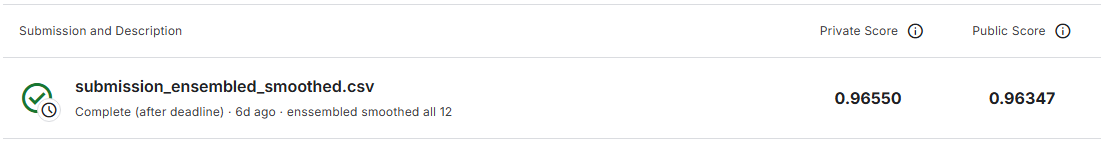

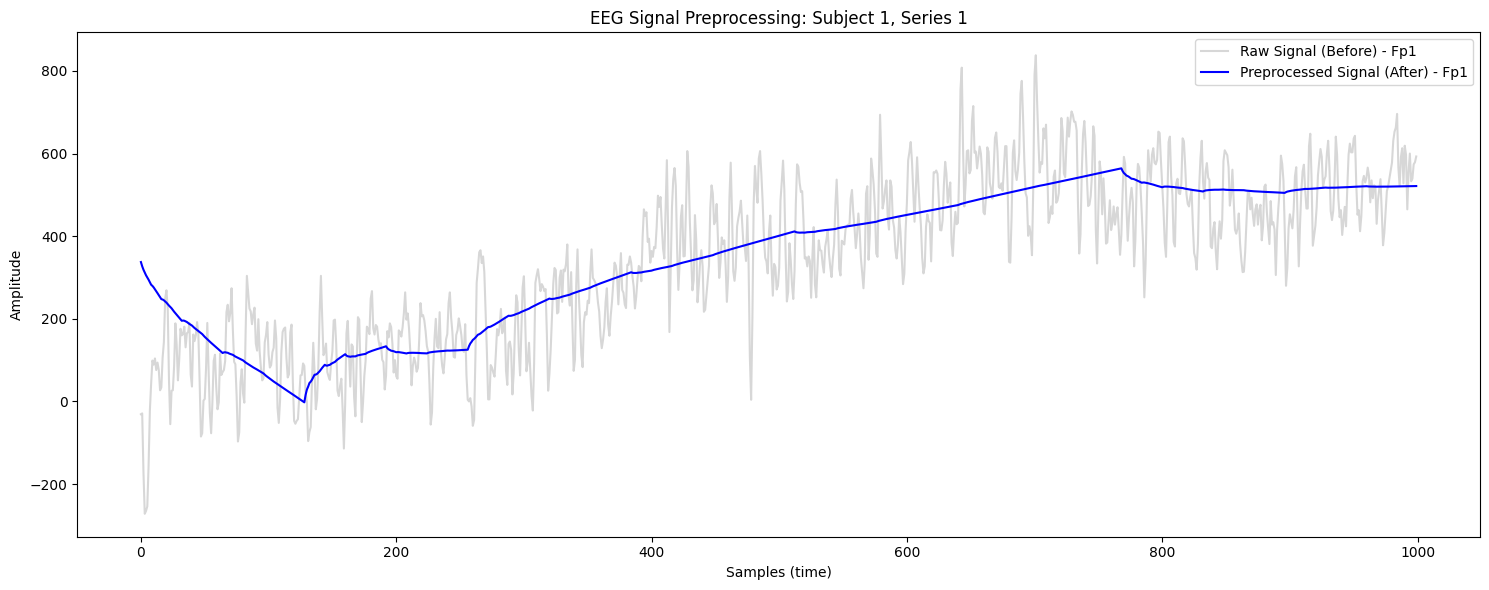

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd


# # 1. Select the subject and series you want to visualize
# subject_id = 1
# series_id = 1

# # 2. Load the raw data for this specific subject and series
# data_path = RAW_TRAIN_DIR / f'subj{subject_id}_series{series_id}_data.csv'
# X_raw_df = pd.read_csv(data_path, usecols=EEG_COLS)
# X_raw = X_raw_df.to_numpy(dtype=np.float32)

# # 3. Apply the wavelet denoising function
# X_denoised = wavelet_denoise_array(X_raw)

# # 4. Plotting
# # Let's plot the first 1000 samples (2 seconds at 500Hz) of the first channel 'Fp1'
# channel_idx = 0 
# num_samples = 1000 
# channel_name = EEG_COLS[channel_idx]

# plt.figure(figsize=(15, 6))

# # Plot Raw Signal in the background
# plt.plot(X_raw[:num_samples, channel_idx], 
#          label=f'Raw Signal (Before) - {channel_name}', 
#          color='lightgray', 
#          alpha=0.9)

# # Plot Denoised Signal on top
# plt.plot(X_denoised[:num_samples, channel_idx], 
#          label=f'Preprocessed Signal (After) - {channel_name}', 
#          color='blue', 
#          linewidth=1.5)

# plt.title(f'EEG Signal Preprocessing: Subject {subject_id}, Series {series_id}')
# plt.xlabel('Samples (time)')
# plt.ylabel('Amplitude')
# plt.legend(loc='upper right')
# plt.tight_layout()

# # Save the plot if you want to keep it
# plt.savefig(f'subj{subject_id}_series{series_id}_preprocessing_comparison.png', dpi=120)
# plt.show()

Loading 12-model ensemble...
Running ensemble inference...


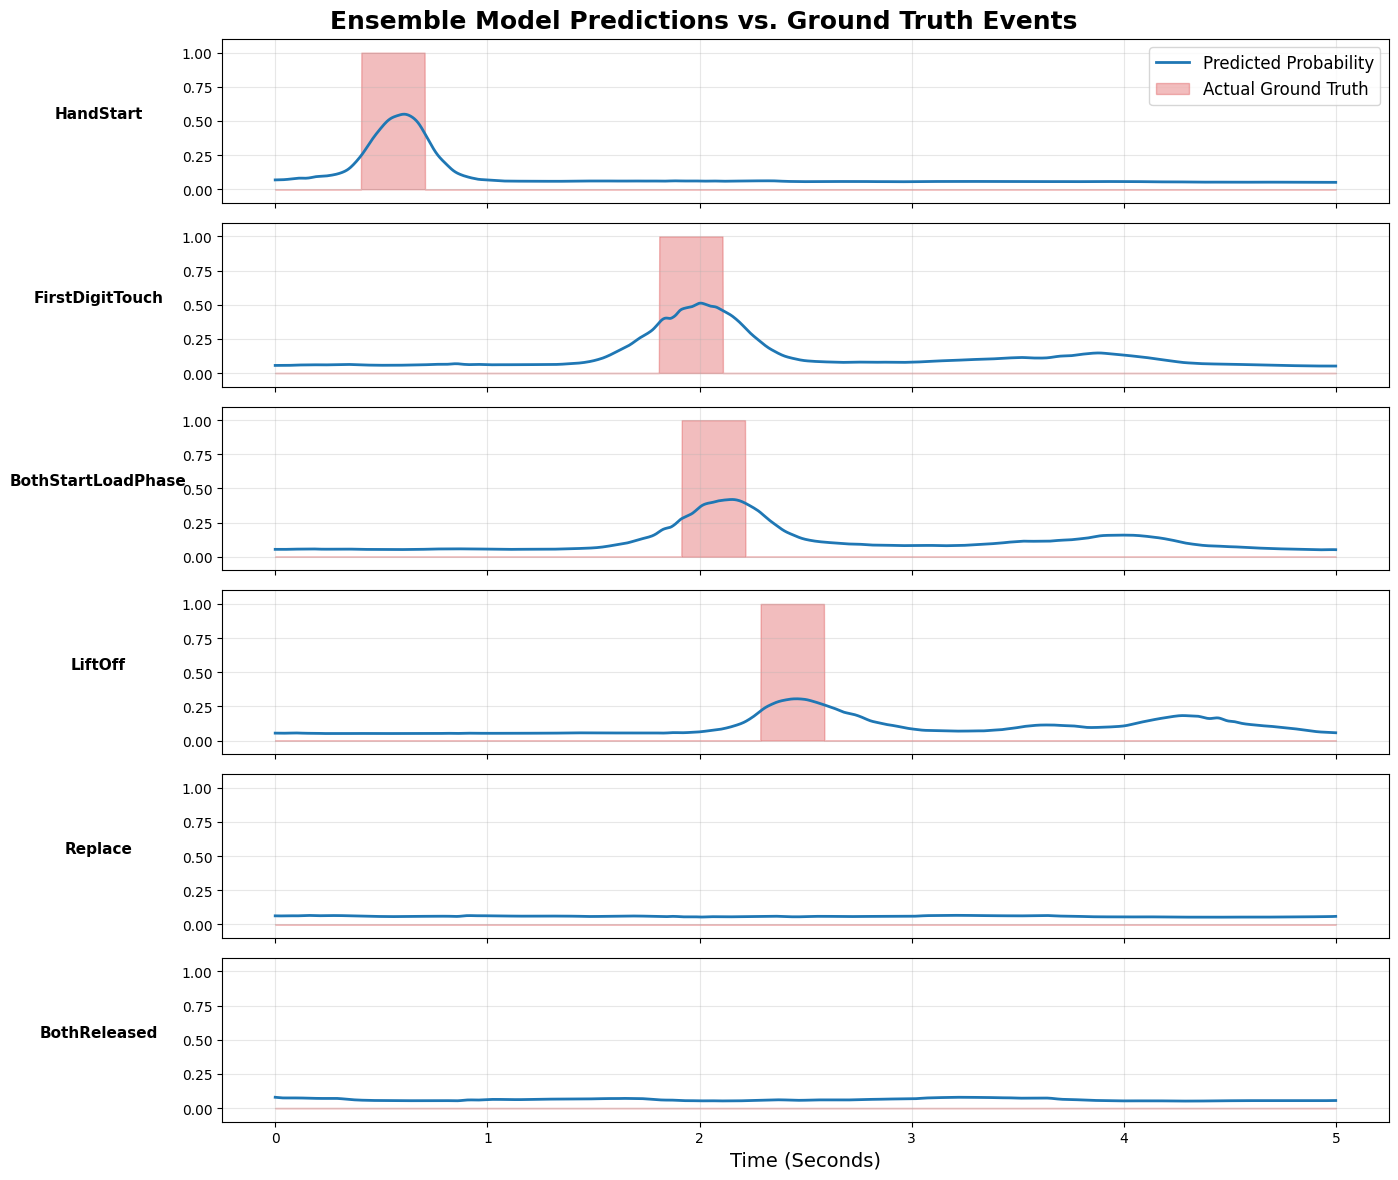

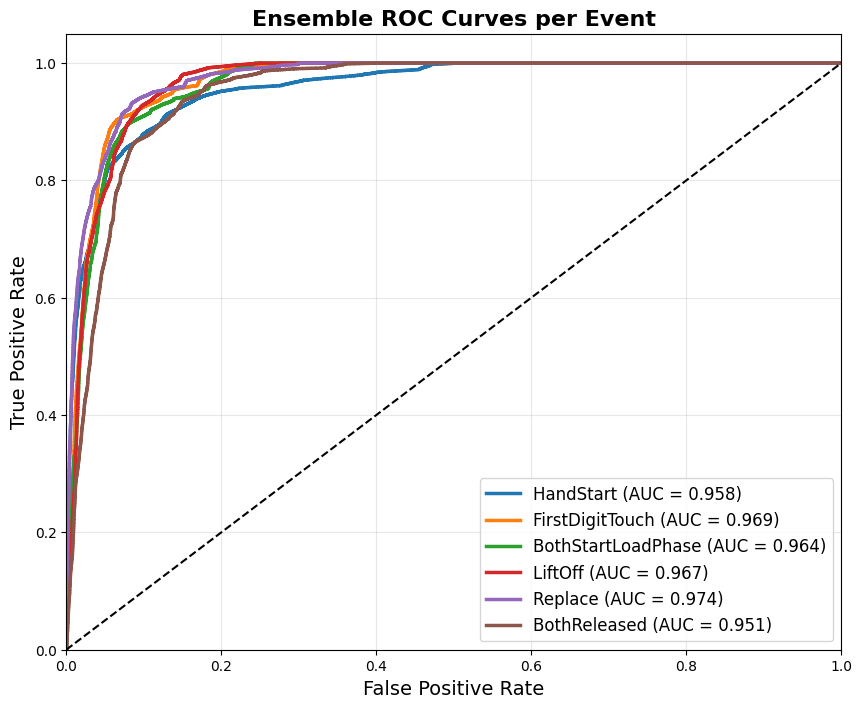

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# import torch
# from sklearn.metrics import roc_curve, auc

# # ---------------------------------------------------------
# # SETUP: Run ENSEMBLE inference on Subject 12, Series 8
# # ---------------------------------------------------------
# val_subj = 12
# val_series = 8 

# # Load raw X and true y
# data_path = RAW_TRAIN_DIR / f'subj{val_subj}_series{val_series}_data.csv'
# event_path = RAW_TRAIN_DIR / f'subj{val_subj}_series{val_series}_events.csv'

# # Read columns explicitly to guarantee correct order
# X_raw = pd.read_csv(data_path)[EEG_COLS].to_numpy(dtype=np.float32)
# y_true = pd.read_csv(event_path)[EVENT_COLS].to_numpy(dtype=np.float32)

# # Preprocess
# X_den = wavelet_denoise_array(X_raw)
# n = X_den.shape[0]

# # Load all 12 fold models and scalers into the ensemble
# print("Loading 12-model ensemble...")
# ensemble = []
# for fold_subj in range(1, NUM_SUBJ + 1):
#     model_path = PROC_DIR / f'best_unet_eeg_fold_{fold_subj}.pt'
#     scaler_path = PROC_DIR / f'scaler_fold_{fold_subj}.npz'
    
#     m = build_model(encoder_name='timm-efficientnet-b3').to(device)
#     m.load_state_dict(torch.load(model_path))
#     m.eval()
    
#     scaler_data = np.load(scaler_path)
#     ensemble.append((m, scaler_data['mean'], scaler_data['scale']))

# # Run Ensemble Inference
# print("Running ensemble inference...")
# probs_chunks = []
# chunk_size = 10000
# with torch.no_grad():
#     for start in range(0, n, chunk_size):
#         Xb_den = X_den[start : start + chunk_size]
        
#         chunk_preds = []
#         for m, sc_mean, sc_scale in ensemble:
#             # Scale input for each specific fold's scaler
#             Xb_sc = (Xb_den - sc_mean) / sc_scale
#             Xt = torch.from_numpy(Xb_sc.T[None]).to(device)
            
#             logits = m(Xt)
#             probs = torch.sigmoid(logits).cpu().numpy()[0]
#             chunk_preds.append(probs)
            
#         # Average the 12 predictions
#         avg_probs = np.mean(chunk_preds, axis=0) 
#         probs_chunks.append(avg_probs)

# probs_series = np.concatenate(probs_chunks, axis=1).T[:n]
# probs_series_smoothed = causal_smooth(probs_series, window=25)


# # ---------------------------------------------------------
# # PLOT 1: Time-Series Prediction Traces
# # ---------------------------------------------------------
# # Visualize 5 seconds of data (2500 samples at 500Hz)
# time_steps = 2500 
# start_idx = 1000 # Offset to find an active part of the signal
# t = np.arange(time_steps) / 500.0 

# fig, axs = plt.subplots(6, 1, figsize=(14, 12), sharex=True)
# fig.suptitle('Ensemble Model Predictions vs. Ground Truth Events', fontsize=18, fontweight='bold', y=0.98)

# for i, event in enumerate(EVENT_COLS):
#     ax = axs[i]
#     ax.plot(t, probs_series_smoothed[start_idx:start_idx+time_steps, i], color='#1f77b4', lw=2, label='Predicted Probability')
#     ax.fill_between(t, 0, y_true[start_idx:start_idx+time_steps, i], color='#d62728', alpha=0.3, label='Actual Ground Truth')
    
#     ax.set_ylabel(event, rotation=0, labelpad=60, ha='center', fontsize=11, fontweight='bold')
#     ax.set_ylim(-0.1, 1.1)
#     ax.grid(alpha=0.3)
#     if i == 0:
#         ax.legend(loc='upper right', fontsize=12)

# plt.xlabel('Time (Seconds)', fontsize=14)
# plt.tight_layout()
# plt.savefig('prediction_traces.png', dpi=150, bbox_inches='tight')
# plt.show()


# # ---------------------------------------------------------
# # PLOT 2: ROC-AUC Curves
# # ---------------------------------------------------------
# plt.figure(figsize=(10, 8))
# colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# for i, event in enumerate(EVENT_COLS):
#     fpr, tpr, _ = roc_curve(y_true[:, i], probs_series_smoothed[:, i])
#     roc_auc = auc(fpr, tpr)
#     plt.plot(fpr, tpr, color=colors[i], lw=2.5, label=f'{event} (AUC = {roc_auc:.3f})')

# plt.plot([0, 1], [0, 1], color='black', lw=1.5, linestyle='--')
# plt.xlim([0.0, 1.0])
# plt.ylim([0.0, 1.05])
# plt.xlabel('False Positive Rate', fontsize=14)
# plt.ylabel('True Positive Rate', fontsize=14)
# plt.title('Ensemble ROC Curves per Event', fontsize=16, fontweight='bold')
# plt.legend(loc="lower right", fontsize=12)
# plt.grid(alpha=0.3)

# plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
# plt.show()